# GIRO 2026 — completing a correlation matrix

Team members: Tim Harrison, Paul Hewson and Xinbin Xu.

[Interactive demo](https://xinbin1011.github.io/vine-matrix-completion/) ·
[Python package and source](https://github.com/Xinbin1011/vine-matrix-completion) ·
[D10 slides](../docs/resources/GIRO_2026_D10_slides.pdf)

**Question.** Five standardised risk variables have six supplied pairwise correlations
and four gaps. Complete the matrix while preserving the supplied information,
making the extra assumptions visible and checking the result.

This notebook calls the shared `vine_completion` package used by the demo.
It contains the worked calculation, rather than a second implementation of the
completion algorithm. The inputs are illustrative **ordinary Pearson correlations**.
They do not specify marginal distributions or a copula family.


## 1. Load the shared package

Run from the repository root or its `notebooks/` folder. In a Python environment,
install the package and optional plotting support with `python -m pip install -e ".[plot]"`.
NumPy and NetworkX perform the calculations; Matplotlib is used only for the diagrams.
No model API or external data is used.


In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import networkx as nx
import matplotlib
import matplotlib.pyplot as plt

candidates = (Path.cwd(), Path.cwd().parent, Path.cwd() / "vine-matrix-completion")
repo_root = next((p for p in candidates if (p / "src" / "vine_completion").is_dir()), None)
if repo_root is None:
    raise RuntimeError("Open this notebook from the repository root or its notebooks folder.")
sys.path.insert(0, str(repo_root / "src"))

from vine_completion import build_vine, complete_matrix, correlation_from_partial, matrix_to_graph
from vine_completion.partials import conditional_moments, edge_key

np.set_printoptions(precision=6, suppress=True, linewidth=100)
print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | NetworkX {nx.__version__}")


Python 3.12.14 | NumPy 2.3.5 | NetworkX 3.7


## 2. Specify the information

`np.nan` marks an unknown entry. A supplied zero would remain a fixed observation.
Missing entries must be symmetric; the diagonal is one.

These are the explorer's **rounded GIRO inputs**. D10 rounds the displayed
figures further; the computation below retains every supplied decimal.
The original full-precision covariance example is separate, at the end.


In [2]:
R = np.array([
    [1,     -.586, np.nan,  .309, -.374],
    [-.586, 1,      .540,  -.785, np.nan],
    [np.nan, .540,  1,     -.059, np.nan],
    [.309, -.785,  -.059,   1,    np.nan],
    [-.374, np.nan, np.nan, np.nan, 1],
])
observed = np.isfinite(R)
missing_pairs = [(i, j) for i in range(len(R)) for j in range(i + 1, len(R)) if not observed[i, j]]
print("Incomplete Pearson correlation matrix (nan = unknown):")
print(R)
pair_count = len(R) * (len(R) - 1) // 2
print(f"\n{len(R)} variables; {pair_count - len(missing_pairs)} supplied pairs; {len(missing_pairs)} missing pairs.")


Incomplete Pearson correlation matrix (nan = unknown):
[[ 1.    -0.586    nan  0.309 -0.374]
 [-0.586  1.     0.54  -0.785    nan]
 [   nan  0.54   1.    -0.059    nan]
 [ 0.309 -0.785 -0.059  1.       nan]
 [-0.374    nan    nan    nan  1.   ]]

5 variables; 6 supplied pairs; 4 missing pairs.


Observed graph is chordal: True


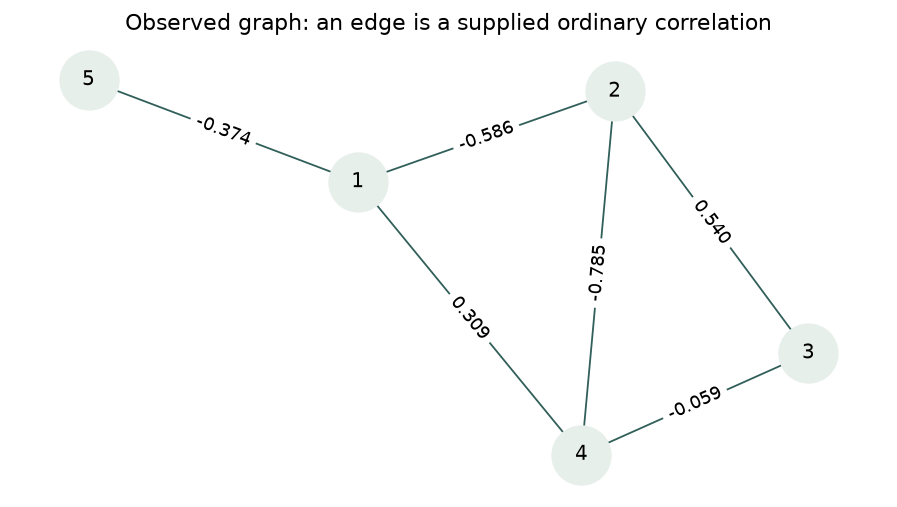

In [3]:
graph = matrix_to_graph(R)
print("Observed graph is chordal:", nx.is_chordal(graph))

fig, ax = plt.subplots(figsize=(7, 4))
pos = nx.spring_layout(graph, seed=7, weight=None)
nx.draw_networkx(graph, pos, ax=ax, node_color="#e7efeb", node_size=1050,
                 edge_color="#315f59", font_size=11)
nx.draw_networkx_edge_labels(graph, pos, ax=ax,
    edge_labels={(u, v): f"{d['weight']:.3f}" for u, v, d in graph.edges(data=True)}, font_size=10)
ax.set_title("Observed graph: an edge is a supplied ordinary correlation")
ax.set_axis_off()
fig.tight_layout()
plt.show()


## 3. Inspect the vine and state the free partials

The package's deterministic greedy rule prioritises edges whose partial correlations
can be calculated from supplied information, then absolute strength. This is one
choice of vine structure. The package checks spanning trees and the regular-vine
proximity condition.

A dot denotes partial correlation, for example $\rho_{25\cdot1}$.
The four orange edges below are additional choices, not supplied observations.


In [4]:
vine = build_vine(R, strategy="greedy")
plan = vine.describe(R)
print("Tree  Partial coordinate     From supplied information")
for row in plan:
    value = row["partial_from_observations"]
    shown = "free" if value is None else f"{value:.6f}"
    print(f"{row['tree']:>4}  {row['key']:<22} {shown}")

free_partials = [
    {"conditioned": row["conditioned"], "conditioning": row["conditioning"], "value": 0.0}
    for row in plan if not row["observed_pair"]
]
assert len(free_partials) == 4
print("\nExplicit assumptions for this worked example:")
for item in free_partials:
    print(edge_key(item["conditioned"], item["conditioning"]), "=", item["value"])


Tree  Partial coordinate     From supplied information
   1  1,2                    -0.586000
   1  1,5                    -0.374000
   1  2,4                    -0.785000
   1  2,3                    0.540000
   2  1,4.2                  -0.300826
   2  2,5.1                  free
   2  3,4.2                  0.699836
   3  4,5.1,2                free
   3  1,3.2,4                free
   4  3,5.1,2,4              free

Explicit assumptions for this worked example:
2,5.1 = 0.0
4,5.1,2 = 0.0
1,3.2,4 = 0.0
3,5.1,2,4 = 0.0


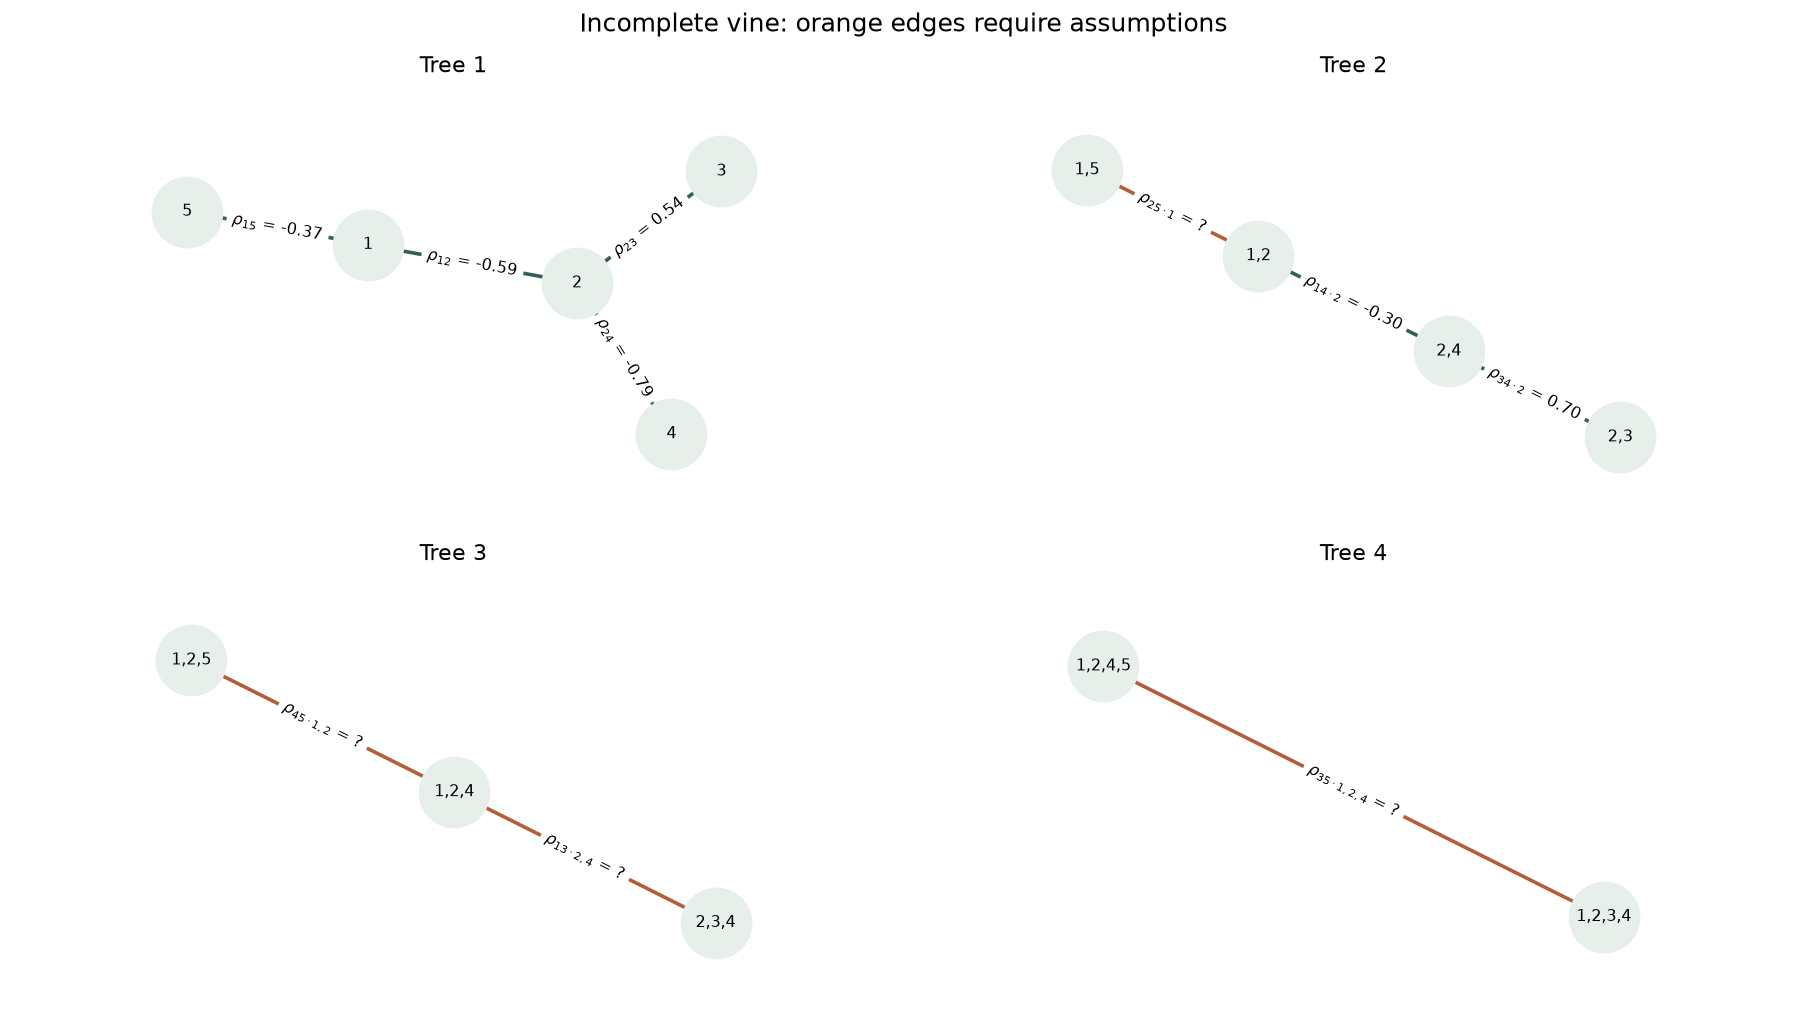

In [5]:
def partial_label(pair, conditioning):
    suffix = r"\cdot" + ",".join(map(str, conditioning)) if conditioning else ""
    return r"$\rho_{" + "".join(map(str, pair)) + suffix + "}$"

lookup = {row["key"]: row["partial_from_observations"] for row in plan}
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for level, (tree, ax) in enumerate(zip(vine.trees, axes.flat), 1):
    positions = nx.spring_layout(tree, seed=7, weight=None)
    labels = {node: ",".join(map(str, sorted(data["variables"]))) for node, data in tree.nodes(data=True)}
    nx.draw_networkx_nodes(tree, positions, ax=ax, node_color="#e7efeb", node_size=1500)
    nx.draw_networkx_labels(tree, positions, labels=labels, ax=ax, font_size=9)
    edge_labels = {}
    for u, v, data in tree.edges(data=True):
        key = edge_key(data["conditioned"], data["conditioning"])
        value = lookup[key]
        colour = "#b45e38" if value is None else "#315f59"
        nx.draw_networkx_edges(tree, positions, edgelist=[(u, v)], ax=ax, edge_color=colour, width=2)
        edge_labels[(u, v)] = partial_label(data["conditioned"], data["conditioning"]) + (
            " = ?" if value is None else f" = {value:.2f}")
    nx.draw_networkx_edge_labels(tree, positions, edge_labels=edge_labels, ax=ax, font_size=9)
    ax.set_title(f"Tree {level}")
    ax.margins(0.30)
    ax.set_axis_off()
fig.suptitle("Incomplete vine: orange edges require assumptions", fontsize=14)
fig.tight_layout()
plt.show()


## 4. Reconstruct a missing correlation

For the first free edge,

$$\rho_{25}=\rho_{21}\rho_{51}
  +\rho_{25\cdot1}\sqrt{(1-\rho_{21}^{2})(1-\rho_{51}^{2})}.$$

The known contribution is $(-0.586)(-0.374)=0.219164$.
Choosing $\rho_{25\cdot1}=0$ therefore gives $\rho_{25}=0.219164$.
The following call uses the package's general reverse-partial calculation.


In [6]:
cross, variance_2, variance_5 = conditional_moments(R, 2, 5, (1,))
scale = np.sqrt(variance_2 * variance_5)
rho_25 = correlation_from_partial(R, 2, 5, (1,), 0.0)
print(f"rho_25 = {cross:.6f} + 0.000000 × {scale:.6f} = {rho_25:.6f}")
assert np.isclose(rho_25, .219164, atol=1e-12, rtol=0)


rho_25 = 0.219164 + 0.000000 × 0.751506 = 0.219164


## 5. Complete the matrix and check the result

All four free partials are supplied explicitly. `missing="error"` prevents the
package from silently filling an unspecified assumption. It reconstructs in tree
order and rejects incompatible choices while preserving the supplied entries.

Zero partials on an arbitrary vine do **not** generally guarantee validity or
maximum determinant. For this example we check both validity and the numerical
maximum-determinant certificate, then compare with the separate chordal policy.


In [7]:
result = complete_matrix(R, kind="correlation", method="vine", strategy="greedy",
                         partials=free_partials, missing="error")
print("Completed Pearson correlation matrix:")
print(result.correlation)
print("\nInferred pairs:")
for i, j in missing_pairs:
    print(f"rho_{i + 1}{j + 1} = {result.correlation[i, j]:.6f}")


Completed Pearson correlation matrix:
[[ 1.       -0.586    -0.460023  0.309    -0.374   ]
 [-0.586     1.        0.54     -0.785     0.219164]
 [-0.460023  0.54      1.       -0.059     0.172049]
 [ 0.309    -0.785    -0.059     1.       -0.115566]
 [-0.374     0.219164  0.172049 -0.115566  1.      ]]

Inferred pairs:
rho_13 = -0.460023
rho_25 = 0.219164
rho_35 = 0.172049
rho_45 = -0.115566


In [8]:
maximum_determinant = complete_matrix(R, kind="correlation", method="max_entropy")
agreement = float(np.max(np.abs(result.correlation - maximum_determinant.correlation)))
d = result.diagnostics
print(f"Minimum eigenvalue:       {d['minimum_eigenvalue_correlation']:.9f}")
print(f"Supplied-entry error:     {d['maximum_observed_error_correlation']:.3g}")
print(f"log det(R):               {d['log_determinant_correlation']:.9f}")
print(f"det(R):                   {np.linalg.det(result.correlation):.9f}")
print(f"Free precision residual:  {d['free_precision_max_abs']:.3g}")
print(f"Chordal-policy agreement: {agreement:.3g}")
print("Maximum determinant certified:", d["max_entropy_certified"])

assert np.array_equal(result.correlation[observed], R[observed])
assert d["minimum_eigenvalue_correlation"] > 1e-10
assert d["max_entropy_certified"]
assert agreement < 1e-12


Minimum eigenvalue:       0.066817176
Supplied-entry error:     0
log det(R):               -2.641548775
det(R):                   0.071250833
Free precision residual:  1.02e-15
Chordal-policy agreement: 1.94e-16
Maximum determinant certified: True


The free-position entries of $R^{-1}$ are numerically zero. Together with positive
definiteness and preserved observations, this is the stationarity certificate for
maximum log determinant under the **original observed-entry constraints**.
It is separate from the feasibility checks and does not certify a different
optimisation problem with additional partial-correlation constraints.

With a multivariate Gaussian model and fixed variances, maximum determinant also
maximises differential entropy. Gaussianity is an additional model assumption.


## 6. Separate a modelling choice from the completion objective

For three variables, two ordinary correlations of 0.5 leave one gap.
Maximum determinant gives 0.25. Supplying the partial correlation
$\rho_{13\cdot2}=0.4$ instead gives $\rho_{13}=0.55$.
The extra partial-correlation assumption changes the question being answered.


In [9]:
three = np.array([[1, .5, np.nan], [.5, 1, .5], [np.nan, .5, 1]])
baseline = complete_matrix(three, method="max_entropy")
alternative = complete_matrix(three, method="vine", strategy="d-vine", order=[1, 2, 3],
    partials=[{"conditioned": [1, 3], "conditioning": [2], "value": .4}], missing="error")
print(f"Maximum determinant, with only the two observations: rho_13 = {baseline.correlation[0, 2]:.2f}")
print(f"Explicit partial rho_13·2 = 0.4:                     rho_13 = {alternative.correlation[0, 2]:.2f}")
assert np.isclose(baseline.correlation[0, 2], .25)
assert np.isclose(alternative.correlation[0, 2], .55)


Maximum determinant, with only the two observations: rho_13 = 0.25
Explicit partial rho_13·2 = 0.4:                     rho_13 = 0.55


## Optional: the original full-precision covariance example

The repository's `five_by_five.json` example retains the original covariance
units and full-precision standardisation. It is a distinct preset from the
rounded GIRO inputs above. Small numerical differences are expected.


In [10]:
example = json.loads((repo_root / "examples" / "five_by_five.json").read_text(encoding="utf-8"))
covariance_result = complete_matrix(example["matrix"], kind="covariance", method="max_entropy")
original_covariance = np.asarray(example["matrix"], dtype=float)
covariance_missing_pairs = [(i, j) for i in range(len(original_covariance))
    for j in range(i + 1, len(original_covariance)) if not np.isfinite(original_covariance[i, j])]
print("Completed covariance matrix (original units):")
print(covariance_result.matrix)
print("\nThe four previously missing covariances:")
for i, j in covariance_missing_pairs:
    print(f"M_{i + 1}{j + 1} = {covariance_result.matrix[i, j]:.6f}")


Completed covariance matrix (original units):
[[ 35.       -25.       -16.777963  10.       -15.      ]
 [-25.        52.        24.       -31.        10.714286]
 [-16.777963  24.        38.        -2.         7.190556]
 [ 10.       -31.        -2.        30.        -4.285714]
 [-15.        10.714286   7.190556  -4.285714  46.      ]]

The four previously missing covariances:
M_13 = -16.777963
M_25 = 10.714286
M_35 = 7.190556
M_45 = -4.285714


## Scope and resources

- The default exact maximum-determinant policy supports **chordal** observation
  graphs with positive definite specified cliques. General nonchordal optimisation
  and singular positive semidefinite completions are not implemented.
- Explicit-vine choices can be incompatible. A rejected choice does not prove
  that the original partially specified matrix has no feasible completion.
- A correlation matrix does not identify margins, a copula family, tail dependence
  or a direction of capital change. This is not an empirical insurance calibration.
- A partial correlation describes regression residuals. It is not generally a
  correlation conditional on fixed values of the other variables.

**Use the [demo](https://xinbin1011.github.io/vine-matrix-completion/) to change
inputs and assumptions, the [D10 slides](../docs/resources/GIRO_2026_D10_slides.pdf)
for the conference walkthrough, and the
[repository](https://github.com/Xinbin1011/vine-matrix-completion) to reuse the code.**

Theory: [Kurowicka and Cooke (2006), *Completion problem with partial correlation
vines*](https://doi.org/10.1016/j.laa.2006.01.031). The code was extracted from the
existing research notebook into the shared package. Codex assisted with packaging,
presentation and validation. Earlier notebooks and versions are preserved separately.
